# Tentativo 16 · 4. Embedding + modelli lineari

Ogni articolo diventa un **vettore** prodotto da un modello nato per gli embedding (**Qwen3-Embedding**), usato così
com'è, **senza addestrarlo**: legge l'articolo intero (gli articoli arrivano al più a 1.500 parole, circa 2.000 token)
con un'istruzione che dice a che cosa serve il vettore. Sopra i vettori, gli **stessi modelli lineari** del notebook 3,
nelle stesse sei configurazioni e sugli stessi fold: così il confronto con il TF-IDF riguarda solo la rappresentazione.

| | che cosa impara | su quali articoli | come si decide la testata |
|---|---|---|---|
| **1. 5 classi** | il livello (l1…l5) | tutti | voto degli articoli |
| **2. binario** | affidabile sì/no (punteggio ≥ 60) | tutti | voto degli articoli |
| **3. binario sugli estremi** | affidabile sì/no | solo l1, l2, l4, l5 | voto degli articoli |
| **4. regressione** | il punteggio 0–100 | tutti | media dei punteggi previsti |
| **5. regressione bilanciata** | il punteggio 0–100, ogni livello pesa uguale | tutti | media dei punteggi previsti |
| **6. regressione sugli estremi** | il punteggio 0–100 | solo l1, l2, l4, l5 | media dei punteggi previsti |

Per le regressioni i 5 livelli si ricavano con le **quote del training** (le testate si ordinano per punteggio previsto
e si tagliano con le stesse quote di livelli del training) e "affidabile" = punteggio previsto ≥ 60.

In [1]:
MODELLO = "Qwen/Qwen3-Embedding-0.6B"      # anche "Qwen/Qwen3-Embedding-8B"
MAX_TOKEN = 2304                            # 2.048 per l'articolo più l'istruzione
BATCH = 8
ISTRUZIONE = "Represent this news article to judge the reliability and journalistic standards of the outlet that published it"
GB_GPU = 20                                 # memoria GPU libera necessaria per partire
PROVA = 0                                   # > 0: solo quel numero di articoli per testata (prova veloce, in Results/prova)
ETICHETTA = ""                              # se c'è, i risultati vanno in Results/embedding/<modello>_<etichetta> (per un'altra istruzione)

In [2]:
# Parameters
MODELLO = "Qwen/Qwen3-Embedding-8B"
BATCH = 4


In [3]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

import funzioni as F

warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
OUT = Path("Results/embedding"); OUT.mkdir(parents=True, exist_ok=True)
art = pd.read_csv("Results/dataset/articoli.csv.gz")
t = pd.read_csv("Results/dataset/testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate, 5 fold")
import time
if PROVA:
    art = art.groupby("domain").head(PROVA).reset_index(drop=True); OUT = Path("Results/prova/embedding"); print(f"PROVA: {len(art):,} articoli")
NOME = MODELLO.split("/")[-1] + (f"_{ETICHETTA}" if ETICHETTA else "")
OUT = OUT / NOME; OUT.mkdir(parents=True, exist_ok=True)
registra = lambda m: print(time.strftime("%H:%M:%S"), m, flush=True)

25,524 articoli di 226 testate, 5 fold


## 1. Gli embedding
Una volta sola, senza etichette; si salvano. Con lo 0,6B circa 15 minuti, con l'8B circa 2–3 ore (sulla V100).

In [4]:
# 1.1 un vettore per articolo
f, f_id = OUT / "embedding.npy", OUT / "embedding_article_id.npy"
if f.exists() and f_id.exists() and np.array_equal(np.load(f_id), art.article_id.to_numpy()):
    E = np.load(f)
else:                                                                 # mancano, o il dataset è cambiato: si ricalcolano
    F.aspetta_gpu(GB_GPU, registra)
    E = F.embedding_articoli(art.text.tolist(), MODELLO, MAX_TOKEN, BATCH, ISTRUZIONE, registra)
    np.save(f, E); np.save(f_id, art.article_id.to_numpy())
print(f"{E.shape[0]:,} articoli, vettori di {E.shape[1]} dimensioni")

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Fetching 4 files:  25%|██▌       | 1/4 [00:05<00:15,  5.17s/it]

Fetching 4 files:  50%|█████     | 2/4 [01:50<01:50, 55.15s/it]

Fetching 4 files:  75%|███████▌  | 3/4 [01:56<00:38, 38.76s/it]

Fetching 4 files: 100%|██████████| 4/4 [01:59<00:00, 29.89s/it]

...

09:52:10 18,004/25,524 articoli (3812 s)


10:05:33 20,004/25,524 articoli (4615 s)


10:21:04 22,004/25,524 articoli (5547 s)


10:39:28 24,004/25,524 articoli (6651 s)


25,524 articoli, vettori di 4096 dimensioni


## 2. I sei modelli lineari, fold per fold
Vettori standardizzati sul training di ogni fold; stessi modelli del notebook 3.

In [5]:
# 2.1 addestramento e previsione
from sklearn.preprocessing import StandardScaler

def un_fold(k):
    tr, te = (art.fold != k).to_numpy(), (art.fold == k).to_numpy()
    s = StandardScaler().fit(E[tr])
    out = art.loc[te, ["article_id", "domain"]].reset_index(drop=True)
    return out.assign(**F.modelli_lineari(s.transform(E[tr]), s.transform(E[te]), art.label.to_numpy()[tr], art.score.to_numpy()[tr]))

pa = pd.concat(Parallel(n_jobs=5)(delayed(un_fold)(k) for k in range(1, 6)), ignore_index=True)
pa.to_csv(OUT / "previsioni_articoli.csv", index=False)
print(f"{len(pa):,} articoli previsti")

25,524 articoli previsti


## 3. I risultati

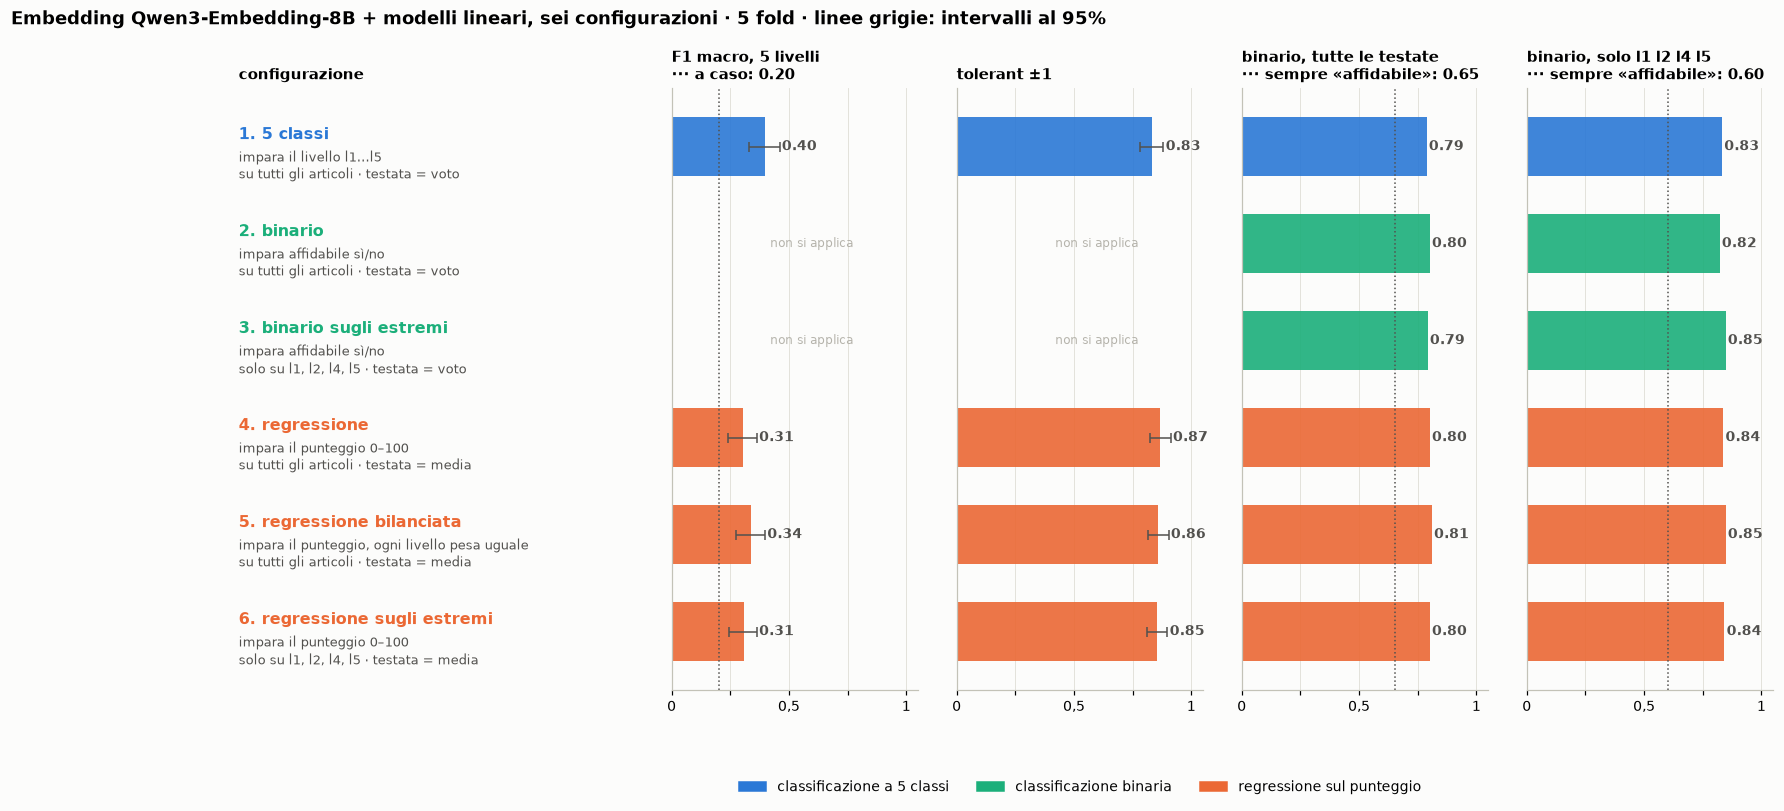

In [6]:
# 3.1 dagli articoli alle testate, le misure (salvate in Results/embedding/<modello>), il grafico
T = F.testate_da_articoli(pa, t); T.to_csv(OUT / "previsioni_testate.csv")
tab5, tab2 = F.misure_testate(T); tab5.to_csv(OUT / "cinque_livelli.csv"); tab2.to_csv(OUT / "binario.csv")
F.grafico_riassunto(T, tab5, tab2, f"Embedding {NOME} + modelli lineari, sei configurazioni · 5 fold · linee grigie: intervalli al 95%", OUT / "riassunto.png")